# AI-Based Autism Spectrum Disorder Screening — AQ-10 Child + Adolescent
Reproducible pipeline for the conference paper. **Run all cells in Google Colab** (Runtime → Run all).
Figures are saved to `figures/`, tables to `tables/`.

Experiments
* **E1 – Naive (leaky)**: all features incl. the `result` score (common in the literature).
* **E2 – Realistic**: AQ-10 items + demographics, `result` removed.
* **E3 – Demographics only**: no questionnaire items.
* **E4 – Reduced questionnaire**: how many AQ-10 items are really needed?
* **E5 – Cross-cohort generalisation**: train on Child → test on Adolescent and vice-versa.

In [1]:
# !pip -q install xgboost lightgbm shap   # uncomment if missing in Colab
import os, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, roc_curve, confusion_matrix,
                             matthews_corrcoef, precision_score, recall_score, make_scorer)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.feature_selection import mutual_info_classif
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from scipy.stats import friedmanchisquare
SEED = 42; np.random.seed(SEED)
os.makedirs('figures', exist_ok=True); os.makedirs('tables', exist_ok=True)
plt.rcParams.update({'figure.dpi':130,'savefig.dpi':300,'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'font.family':'DejaVu Sans'})
PAL = ['#2E5EAA','#E07A2E']   # NO, YES

In [2]:
# ---- Load data (Colab: upload the CSV when prompted) ----
CSV = 'Autism_Combined_Cleaned.csv'
if not os.path.exists(CSV):
    try:
        from google.colab import files; up = files.upload(); CSV = list(up.keys())[0]
    except ImportError:
        CSV = os.environ.get('ASD_CSV', CSV)
df = pd.read_csv(CSV)
print(df.shape); df.head()

(392, 22)


,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,...,ethnicity,jundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD,Dataset_Source
0,0,0,0,1,1,1,1,1,1,0,...,Hispanic,yes,yes,Austria,no,6.0,12-16 years,Parent,NO,Adolescent
1,0,0,0,0,0,0,0,0,1,1,...,Black,no,no,Austria,no,2.0,12-16 years,Relative,NO,Adolescent
2,0,0,0,0,0,0,0,0,1,1,...,?,no,no,AmericanSamoa,no,2.0,12-16 years,?,NO,Adolescent
3,0,1,1,1,1,1,0,1,1,0,...,White-European,no,no,United Kingdom,no,7.0,12-16 years,Self,YES,Adolescent
4,1,1,1,1,1,1,1,0,0,0,...,?,no,no,Albania,no,7.0,12-16 years,?,YES,Adolescent


## 1. Data cleaning & integrity audit

In [3]:
ITEMS = [f'A{i}_Score' for i in range(1,11)]
df['ethnicity'] = df['ethnicity'].str.strip().replace('?', 'Unknown')
df['relation']  = df['relation'].str.strip().replace({'?':'Unknown','self':'Self'})
df['y'] = (df['Class/ASD']=='YES').astype(int)
df['cohort'] = df['Dataset_Source']

# Integrity checks -> Table 1
audit = pd.DataFrame({
 'Check':['Instances','Features (raw)','ASD-positive (%)','Missing ("?") ethnicity','Missing ("?") relation',
          'Duplicate rows','result == sum(A1..A10)','Class == (result > 6)'],
 'Value':[len(df), df.shape[1]-3, f"{df.y.sum()} ({100*df.y.mean():.1f}%)",
          (df.ethnicity=='Unknown').sum(), (df.relation=='Unknown').sum(), df.duplicated().sum(),
          f"{100*(df[ITEMS].sum(1)==df.result).mean():.1f}% of rows",
          f"{100*((df.result>6).astype(int)==df.y).mean():.1f}% of rows"]})
audit.to_csv('tables/table1_audit.csv', index=False); audit

,Check,Value
0,Instances,392
1,Features (raw),21
2,ASD-positive (%),202 (51.5%)
3,"Missing (""?"") ethnicity",46
4,"Missing (""?"") relation",46
5,Duplicate rows,3
6,result == sum(A1..A10),100.0% of rows
7,Class == (result > 6),100.0% of rows


In [4]:
# Table 2 – cohort characteristics
def desc(g):
    return pd.Series({'N':len(g),'Age mean±SD':f"{g.age.mean():.1f}±{g.age.std():.1f}",
      'Male %':f"{100*(g.gender=='m').mean():.1f}",'ASD+ %':f"{100*g.y.mean():.1f}",
      'Jaundice %':f"{100*(g.jundice=='yes').mean():.1f}",'Family ASD %':f"{100*(g.austim=='yes').mean():.1f}",
      'AQ-10 score mean±SD':f"{g.result.mean():.2f}±{g.result.std():.2f}"})
t2 = pd.concat({'Child':desc(df[df.cohort=='Child']),'Adolescent':desc(df[df.cohort=='Adolescent']),'All':desc(df)},axis=1)
t2.to_csv('tables/table2_cohort.csv'); t2

,Child,Adolescent,All
N,288,104,392
Age mean±SD,6.4±2.4,14.1±1.6,8.4±4.1
Male %,70.8,48.1,64.8
ASD+ %,48.3,60.6,51.5
Jaundice %,27.1,15.4,24.0
Family ASD %,17.0,13.5,16.1
AQ-10 score mean±SD,6.25±2.28,6.72±2.20,6.38±2.27


## 2. Exploratory figures

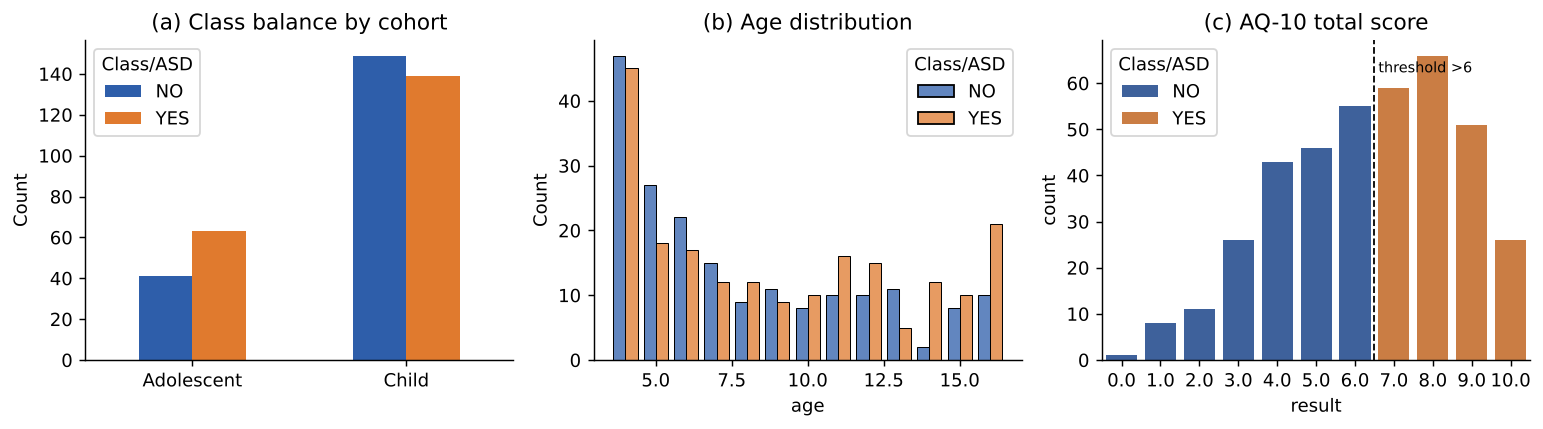

In [5]:
fig,ax = plt.subplots(1,3,figsize=(12,3.4))
ct = pd.crosstab(df.cohort, df['Class/ASD'])
ct.plot.bar(ax=ax[0], color=PAL, rot=0); ax[0].set_title('(a) Class balance by cohort'); ax[0].set_ylabel('Count'); ax[0].set_xlabel('')
sns.histplot(data=df, x='age', hue='Class/ASD', multiple='dodge', discrete=True, palette=PAL, ax=ax[1], shrink=.8)
ax[1].set_title('(b) Age distribution')
sns.countplot(data=df, x='result', hue='Class/ASD', palette=PAL, ax=ax[2])
ax[2].axvline(6.5, ls='--', c='k', lw=1); ax[2].text(6.6, ax[2].get_ylim()[1]*.9,'threshold >6',fontsize=8)
ax[2].set_title('(c) AQ-10 total score'); ax[2].set_xlabel('result')
plt.tight_layout(); plt.savefig('figures/fig1_eda.png', bbox_inches='tight'); plt.show()

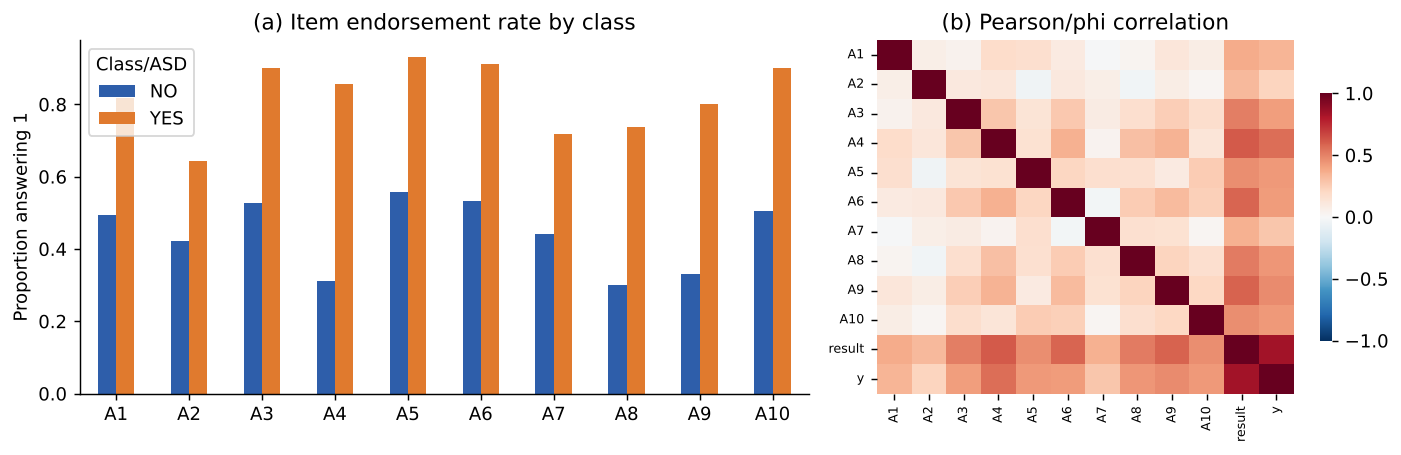

In [6]:
# Item endorsement by class + phi correlation with label
rate = df.groupby('Class/ASD')[ITEMS].mean().T; rate.index=[f'A{i}' for i in range(1,11)]
mi = mutual_info_classif(df[ITEMS], df.y, discrete_features=True, random_state=SEED)
fig,ax = plt.subplots(1,2,figsize=(11,3.6),gridspec_kw={'width_ratios':[1.4,1]})
rate.plot.bar(ax=ax[0], color=PAL, rot=0); ax[0].set_ylabel('Proportion answering 1'); ax[0].set_title('(a) Item endorsement rate by class')
corr = df[ITEMS+['result','y']].corr(); corr.index=corr.columns=[c.replace('_Score','') for c in corr.columns]
sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax[1], cbar_kws={'shrink':.7}, xticklabels=True, yticklabels=True)
ax[1].set_title('(b) Pearson/phi correlation'); ax[1].tick_params(labelsize=7)
plt.tight_layout(); plt.savefig('figures/fig2_items.png', bbox_inches='tight'); plt.show()
pd.DataFrame({'Item':rate.index,'Endorse_NO':rate['NO'].round(3),'Endorse_YES':rate['YES'].round(3),
              'Mutual_info':mi.round(3),'Corr_with_label':corr.loc[rate.index,'y'].round(3)}).to_csv('tables/table3_items.csv',index=False)

## 3. Models and evaluation protocol
Repeated stratified 10-fold CV (5 repeats = 50 folds). Preprocessing (one-hot, scaling) is fitted inside each fold to avoid leakage.

In [7]:
DEMO_CAT = ['gender','ethnicity','jundice','austim','used_app_before','relation','cohort']
DEMO_NUM = ['age']
def models():
    return {
     'LR':  LogisticRegression(max_iter=2000, C=1.0),
     'SVM': SVC(kernel='rbf', C=1.0, probability=True, random_state=SEED),
     'KNN': KNeighborsClassifier(n_neighbors=5),
     'NB':  GaussianNB(),
     'DT':  DecisionTreeClassifier(random_state=SEED),
     'RF':  RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1),
     'AdaBoost': AdaBoostClassifier(n_estimators=200, random_state=SEED),
     'GBM': GradientBoostingClassifier(random_state=SEED),
     'XGBoost': XGBClassifier(n_estimators=300, max_depth=3, learning_rate=.1, eval_metric='logloss', random_state=SEED, verbosity=0, n_jobs=1),
     'LightGBM': LGBMClassifier(n_estimators=300, learning_rate=.05, random_state=SEED, verbose=-1, n_jobs=1),
     'MLP': MLPClassifier(hidden_layer_sizes=(64,32), max_iter=1000, early_stopping=False, random_state=SEED)}

def make_pipe(clf, num, cat):
    pre = ColumnTransformer([('num', StandardScaler(), num),
                             ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat)])
    return Pipeline([('pre', pre), ('clf', clf)])

SCORING = {'Accuracy':'accuracy','Precision':'precision','Recall':'recall','F1':'f1','ROC-AUC':'roc_auc',
           'MCC':make_scorer(matthews_corrcoef)}
CV = RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=SEED)

def run_experiment(num, cat, name):
    X = df[num+cat]; y = df.y; rows = []; folds = {}
    for m, clf in models().items():
        r = cross_validate(make_pipe(clf, num, cat), X, y, cv=CV, scoring=SCORING, n_jobs=-1)
        folds[m] = r['test_Accuracy']
        rows.append({'Model':m, **{k:f"{r['test_'+k].mean():.3f}±{r['test_'+k].std():.3f}" for k in SCORING},
                     **{k+'_mean':r['test_'+k].mean() for k in SCORING}})
    res = pd.DataFrame(rows).sort_values('F1_mean', ascending=False)
    res[['Model']+list(SCORING)].to_csv(f'tables/{name}.csv', index=False)
    return res, pd.DataFrame(folds)

In [8]:
E = {}
E['E1 Naive (items+demo+result)'] = run_experiment(ITEMS+DEMO_NUM+['result'], DEMO_CAT, 'table4_E1_naive')
E['E2 Realistic (items+demo)']    = run_experiment(ITEMS+DEMO_NUM, DEMO_CAT, 'table5_E2_realistic')
E['E3 Demographics only']         = run_experiment(DEMO_NUM, DEMO_CAT, 'table6_E3_demographics')
for k,(r,_) in E.items(): print('\n',k); display(r[['Model']+list(SCORING)])


 E1 Naive (items+demo+result)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,MCC
0,LR,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000
5,RF,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000
4,DT,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000
9,LightGBM,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000
8,XGBoost,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000
6,AdaBoost,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000
7,GBM,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000
10,MLP,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000
1,SVM,0.982±0.022,0.982±0.026,0.983±0.031,0.982±0.021,0.999±0.003,0.964±0.042
2,KNN,0.919±0.046,0.884±0.063,0.977±0.033,0.927±0.040,0.981±0.019,0.846±0.086



 E2 Realistic (items+demo)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,MCC
6,AdaBoost,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000,1.000±0.000
0,LR,0.998±0.008,0.997±0.014,1.000±0.000,0.999±0.007,1.000±0.000,0.997±0.015
10,MLP,0.998±0.007,0.999±0.007,0.997±0.012,0.998±0.007,1.000±0.000,0.996±0.014
1,SVM,0.974±0.026,0.973±0.031,0.977±0.036,0.975±0.026,0.998±0.003,0.949±0.052
8,XGBoost,0.973±0.022,0.964±0.036,0.986±0.024,0.974±0.021,0.996±0.007,0.947±0.044
7,GBM,0.955±0.033,0.948±0.045,0.967±0.041,0.957±0.031,0.991±0.013,0.911±0.065
9,LightGBM,0.953±0.030,0.946±0.042,0.965±0.041,0.954±0.029,0.991±0.012,0.907±0.059
5,RF,0.936±0.038,0.934±0.049,0.944±0.049,0.938±0.037,0.989±0.013,0.873±0.076
2,KNN,0.898±0.049,0.856±0.062,0.972±0.040,0.909±0.042,0.970±0.025,0.807±0.093
4,DT,0.869±0.044,0.872±0.060,0.882±0.074,0.874±0.044,0.869±0.044,0.744±0.088



 E3 Demographics only


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,MCC
3,NB,0.520±0.045,0.521±0.027,0.900±0.096,0.658±0.040,0.595±0.088,0.021±0.157
1,SVM,0.609±0.065,0.611±0.060,0.666±0.101,0.635±0.068,0.611±0.078,0.218±0.133
2,KNN,0.565±0.072,0.568±0.061,0.646±0.107,0.602±0.075,0.586±0.081,0.129±0.149
0,LR,0.566±0.064,0.572±0.059,0.636±0.112,0.598±0.071,0.581±0.087,0.131±0.135
5,RF,0.569±0.061,0.582±0.061,0.606±0.092,0.590±0.062,0.572±0.071,0.139±0.125
7,GBM,0.561±0.069,0.572±0.066,0.604±0.086,0.585±0.066,0.573±0.074,0.119±0.141
8,XGBoost,0.575±0.071,0.589±0.072,0.585±0.103,0.584±0.079,0.581±0.075,0.151±0.142
6,AdaBoost,0.554±0.079,0.562±0.074,0.612±0.124,0.582±0.087,0.568±0.094,0.107±0.161
9,LightGBM,0.552±0.073,0.564±0.071,0.584±0.104,0.571±0.078,0.574±0.079,0.103±0.149
10,MLP,0.535±0.071,0.554±0.078,0.536±0.105,0.540±0.079,0.571±0.080,0.072±0.145


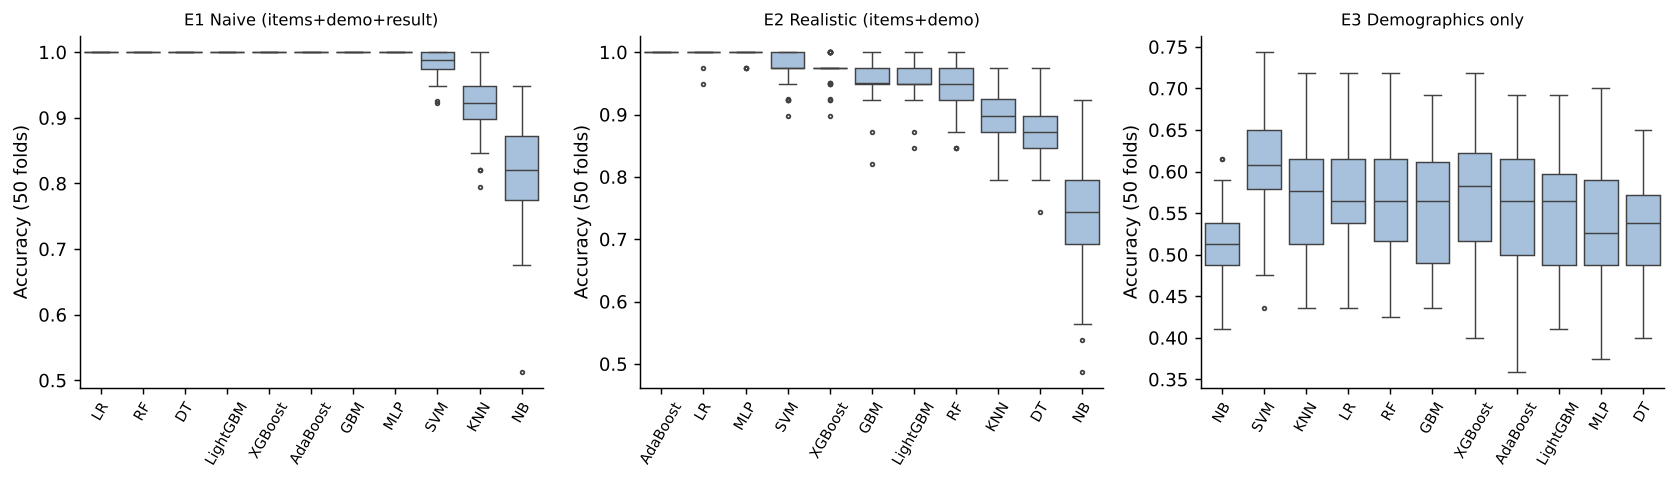

Friedman test E2: chi2=429.49, p=4.93e-86


In [9]:
# Fig 3 – accuracy distribution across 50 folds, three feature settings
fig,ax = plt.subplots(1,3,figsize=(13,3.8),sharey=False)
for a,(k,(r,f)) in zip(ax,E.items()):
    order = r.Model.tolist()
    sns.boxplot(data=f[order], ax=a, color='#9EC1E6', fliersize=2, linewidth=.8)
    a.set_title(k, fontsize=9); a.tick_params(axis='x', rotation=60, labelsize=8); a.set_ylabel('Accuracy (50 folds)')
plt.tight_layout(); plt.savefig('figures/fig3_cv_boxplots.png', bbox_inches='tight'); plt.show()
# Friedman test on E2
_, f2 = E['E2 Realistic (items+demo)']; st,p = friedmanchisquare(*[f2[c] for c in f2])
print(f'Friedman test E2: chi2={st:.2f}, p={p:.2e}')
_, f3 = E['E3 Demographics only']; st3,p3 = friedmanchisquare(*[f3[c] for c in f3])
pd.DataFrame({'Experiment':['E2','E3'],'chi2':[round(st,2),round(st3,2)],'p':[f'{p:.2e}',f'{p3:.2e}']}).to_csv('tables/friedman.csv',index=False)

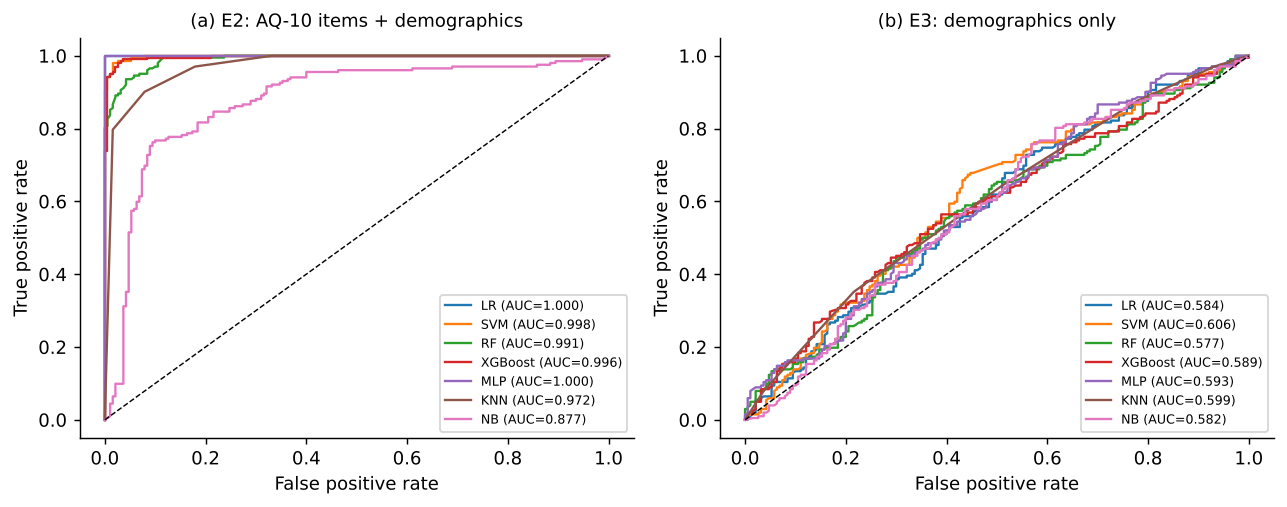

In [10]:
# Fig 4 – ROC curves (E2 vs E3) with out-of-fold predictions
skf = StratifiedKFold(10, shuffle=True, random_state=SEED)
fig,ax = plt.subplots(1,2,figsize=(10,4))
sel = ['LR','SVM','RF','XGBoost','MLP','KNN','NB']
for a,(num,title) in zip(ax,[(ITEMS+DEMO_NUM,'(a) E2: AQ-10 items + demographics'),(DEMO_NUM,'(b) E3: demographics only')]):
    for m in sel:
        p = cross_val_predict(make_pipe(models()[m], num, DEMO_CAT), df[num+DEMO_CAT], df.y, cv=skf, method='predict_proba')[:,1]
        fpr,tpr,_ = roc_curve(df.y,p); a.plot(fpr,tpr,lw=1.3,label=f'{m} (AUC={roc_auc_score(df.y,p):.3f})')
    a.plot([0,1],[0,1],'k--',lw=.8); a.set_xlabel('False positive rate'); a.set_ylabel('True positive rate'); a.set_title(title,fontsize=10); a.legend(fontsize=7,loc='lower right')
plt.tight_layout(); plt.savefig('figures/fig4_roc.png', bbox_inches='tight'); plt.show()

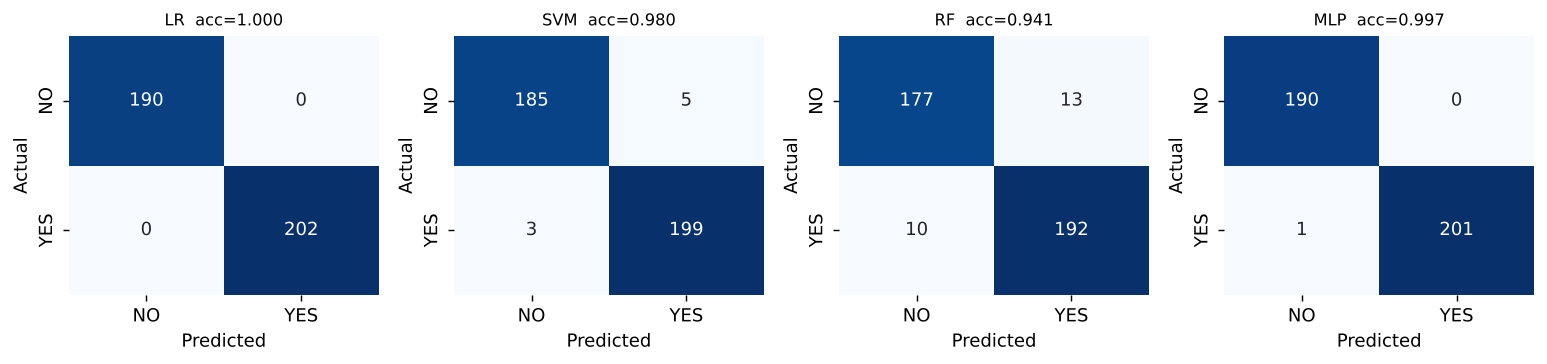

In [11]:
# Fig 5 – confusion matrices (E2) for 4 representative models
fig,ax = plt.subplots(1,4,figsize=(12,2.9))
for a,m in zip(ax,['LR','SVM','RF','MLP']):
    yp = cross_val_predict(make_pipe(models()[m], ITEMS+DEMO_NUM, DEMO_CAT), df[ITEMS+DEMO_NUM+DEMO_CAT], df.y, cv=skf)
    sns.heatmap(confusion_matrix(df.y,yp), annot=True, fmt='d', cmap='Blues', cbar=False, ax=a,
                xticklabels=['NO','YES'], yticklabels=['NO','YES'])
    a.set_title(f'{m}  acc={accuracy_score(df.y,yp):.3f}',fontsize=9); a.set_xlabel('Predicted'); a.set_ylabel('Actual')
plt.tight_layout(); plt.savefig('figures/fig5_confusion.png', bbox_inches='tight'); plt.show()

## 4. Explainability (SHAP) and learned weights

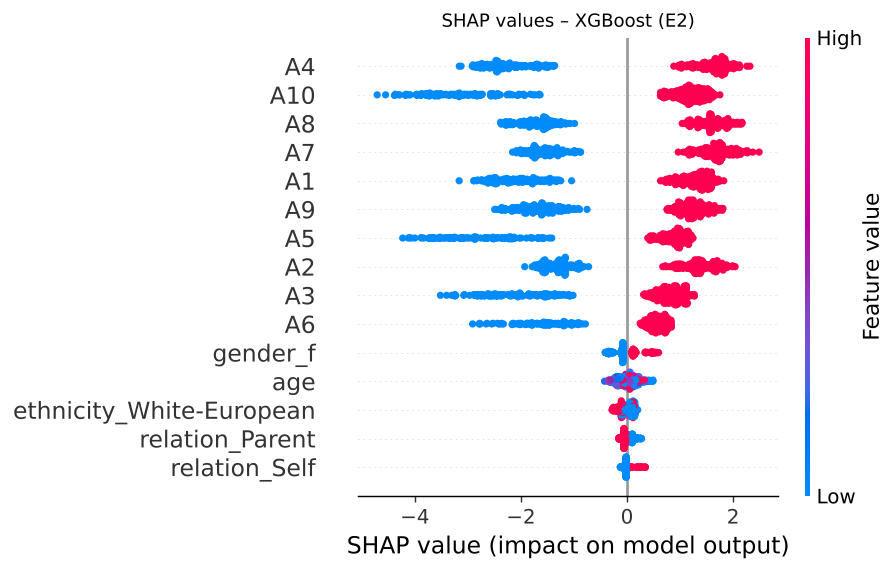

LR item weights: [8.51 8.04 8.08 8.47 8.69 7.84 8.07 8.33 7.88 8.74]  intercept: -53.75  implied threshold = 6.5


In [12]:
import shap
Xi = df[ITEMS+DEMO_NUM+DEMO_CAT]
pipe = make_pipe(XGBClassifier(n_estimators=300,max_depth=3,learning_rate=.1,eval_metric='logloss',random_state=SEED,verbosity=0), ITEMS+DEMO_NUM, DEMO_CAT).fit(Xi, df.y)
Xt = pipe.named_steps['pre'].transform(Xi); names = [n.split('__')[1].replace('_Score','') for n in pipe.named_steps['pre'].get_feature_names_out()]
sv = shap.TreeExplainer(pipe.named_steps['clf']).shap_values(Xt)
plt.figure(); shap.summary_plot(sv, Xt, feature_names=names, max_display=15, show=False, plot_size=(7,4.5))
plt.title('SHAP values – XGBoost (E2)',fontsize=10); plt.tight_layout(); plt.savefig('figures/fig6_shap.png', bbox_inches='tight'); plt.show()
shap_imp = pd.Series(np.abs(sv).mean(0), index=names).sort_values(ascending=False)
shap_imp.round(4).to_csv('tables/shap_importance.csv')
# LR coefficients on raw items: does the model just learn 'sum > 6'?
lr = LogisticRegression(C=100,max_iter=5000).fit(df[ITEMS],df.y)
print('LR item weights:', np.round(lr.coef_[0],2), ' intercept:', round(lr.intercept_[0],2),
      ' implied threshold =', round(-lr.intercept_[0]/lr.coef_[0].mean(),2))

## 5. E4 – Reduced questionnaire (fewer items)

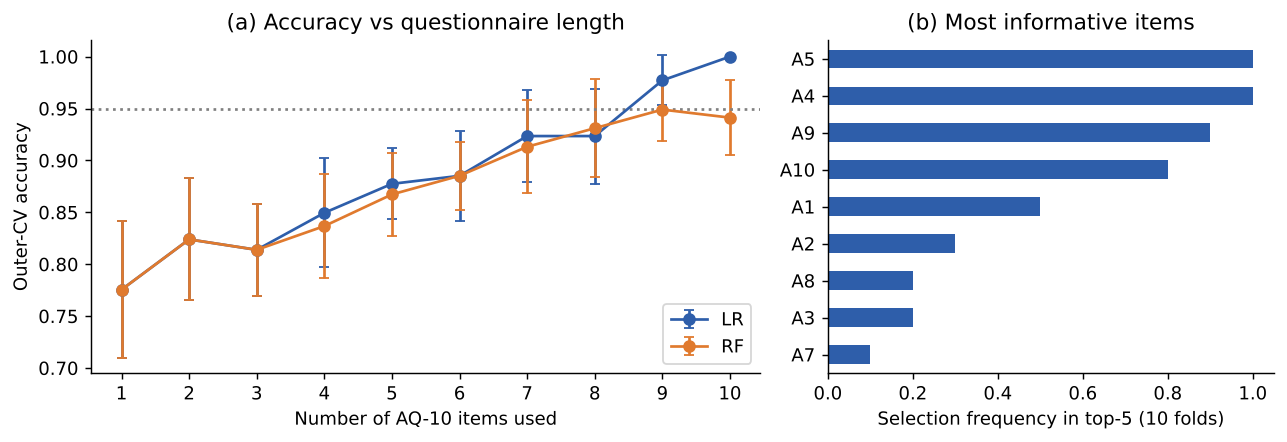

,k,LR_acc,RF_acc,LR_sd,RF_sd
0,1,0.775,0.775,0.066,0.066
1,2,0.824,0.824,0.059,0.059
2,3,0.814,0.814,0.044,0.044
3,4,0.849,0.837,0.053,0.050
4,5,0.877,0.867,0.034,0.040
5,6,0.885,0.885,0.043,0.033
6,7,0.923,0.913,0.044,0.045
7,8,0.923,0.931,0.046,0.047
8,9,0.977,0.949,0.024,0.030
9,10,1.000,0.941,0.000,0.036


In [13]:
# Greedy forward selection of items, evaluated with nested-style CV (selection is re-done inside each outer fold)
def greedy_order(X, y):
    chosen, rest = [], list(ITEMS)
    while rest:
        best = max(rest, key=lambda c: cross_val_predict(LogisticRegression(max_iter=2000), X[chosen+[c]], y,
                     cv=StratifiedKFold(5,shuffle=True,random_state=SEED)).__eq__(y).mean())
        chosen.append(best); rest.remove(best)
    return chosen
outer = StratifiedKFold(10, shuffle=True, random_state=SEED)
acc = {k:{'LR':[],'RF':[]} for k in range(1,11)}; orders=[]
for tr,te in outer.split(df,df.y):
    Xtr,ytr,Xte,yte = df.iloc[tr],df.y.iloc[tr],df.iloc[te],df.y.iloc[te]
    o = greedy_order(Xtr,ytr); orders.append(o)
    for k in range(1,11):
        for m,clf in [('LR',LogisticRegression(max_iter=2000)),('RF',RandomForestClassifier(300,random_state=SEED,n_jobs=-1))]:
            acc[k][m].append(accuracy_score(yte, clf.fit(Xtr[o[:k]],ytr).predict(Xte[o[:k]])))
e4 = pd.DataFrame([{'k':k, **{f'{m}_acc':np.mean(v[m]) for m in v}, **{f'{m}_sd':np.std(v[m]) for m in v}} for k,v in acc.items()])
first = pd.Series([o[0] for o in orders]).value_counts(); top5 = pd.Series([c for o in orders for c in o[:5]]).value_counts()
e4.round(3).to_csv('tables/table7_E4_reduced.csv', index=False)
fig,ax = plt.subplots(1,2,figsize=(10,3.5),gridspec_kw={'width_ratios':[1.5,1]})
for m,c in [('LR','#2E5EAA'),('RF','#E07A2E')]:
    ax[0].errorbar(e4.k, e4[f'{m}_acc'], yerr=e4[f'{m}_sd'], marker='o', capsize=3, label=m, color=c)
ax[0].axhline(.95,ls=':',c='gray'); ax[0].set_xlabel('Number of AQ-10 items used'); ax[0].set_ylabel('Outer-CV accuracy'); ax[0].set_title('(a) Accuracy vs questionnaire length'); ax[0].legend(); ax[0].set_xticks(range(1,11))
(top5/10).sort_values().plot.barh(ax=ax[1], color='#2E5EAA'); ax[1].set_xlabel('Selection frequency in top-5 (10 folds)'); ax[1].set_title('(b) Most informative items')
ax[1].set_yticklabels([t.get_text().replace('_Score','') for t in ax[1].get_yticklabels()])
plt.tight_layout(); plt.savefig('figures/fig7_reduced_items.png', bbox_inches='tight'); plt.show(); e4.round(3)

## 6. E5 – Cross-cohort generalisation

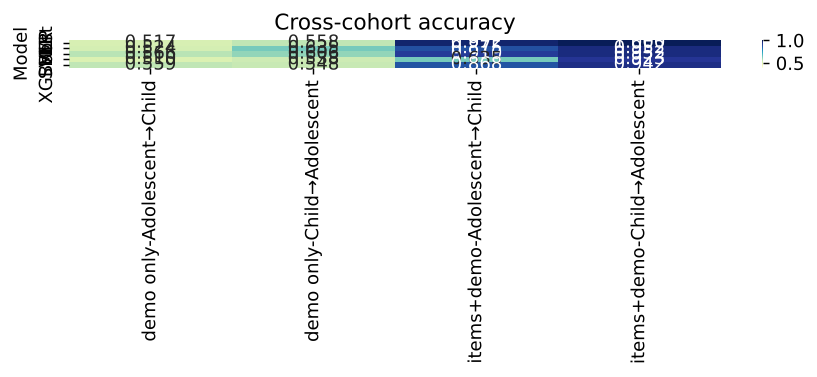

Features          demo only                        items+demo                 
Train→Test Adolescent→Child Child→Adolescent Adolescent→Child Child→Adolescent
Model                                                                         
LR                    0.517            0.558            0.972            1.000
MLP                   0.524            0.635            0.875            0.952
RF                    0.566            0.606            0.910            0.952
SVM                   0.510            0.538            0.635            0.923
XGBoost               0.559            0.548            0.868            0.942

In [14]:
cross=[]; num=ITEMS+DEMO_NUM; cat=[c for c in DEMO_CAT if c!='cohort']
for tr_c,te_c in [('Child','Adolescent'),('Adolescent','Child')]:
    tr,te = df[df.cohort==tr_c], df[df.cohort==te_c]
    for m in ['LR','SVM','RF','XGBoost','MLP']:
        for feats,lab in [(num,'items+demo'),(DEMO_NUM,'demo only')]:
            p = make_pipe(models()[m], feats, cat).fit(tr[feats+cat], tr.y)
            pr = p.predict_proba(te[feats+cat])[:,1]
            cross.append({'Train→Test':f'{tr_c}→{te_c}','Features':lab,'Model':m,
                          'Accuracy':accuracy_score(te.y,pr>.5),'F1':f1_score(te.y,pr>.5),'ROC-AUC':roc_auc_score(te.y,pr)})
cross = pd.DataFrame(cross); cross.round(3).to_csv('tables/table8_E5_cross.csv', index=False)
piv = cross.pivot_table(index='Model', columns=['Features','Train→Test'], values='Accuracy')
plt.figure(figsize=(7,3)); sns.heatmap(piv, annot=True, fmt='.3f', cmap='YlGnBu', vmin=.4, vmax=1)
plt.title('Cross-cohort accuracy'); plt.xlabel(''); plt.tight_layout(); plt.savefig('figures/fig8_cross_cohort.png', bbox_inches='tight'); plt.show(); piv.round(3)

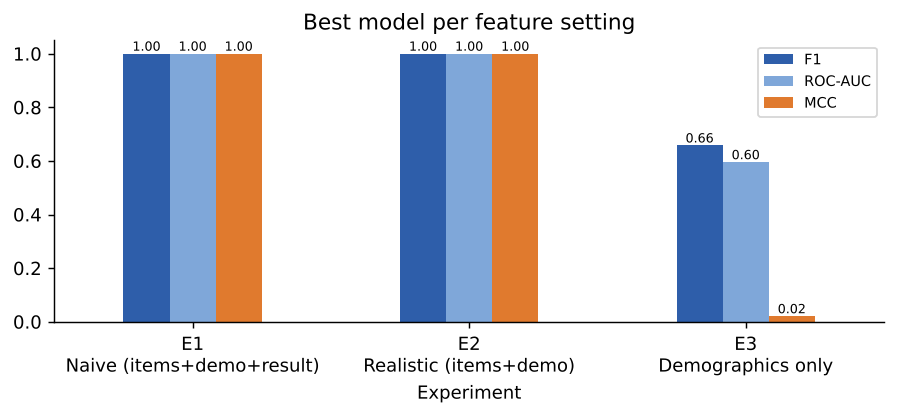

,Experiment,Best model,F1,ROC-AUC,MCC
0,E1\nNaive (items+demo+result),LR,1.000000,1.000000,1.000000
1,E2\nRealistic (items+demo),AdaBoost,1.000000,1.000000,1.000000
2,E3\nDemographics only,NB,0.657556,0.595244,0.020519


In [15]:
# Fig 9 – summary: best F1 per experiment
summ = pd.DataFrame([{'Experiment':k.split(' ',1)[0]+'\n'+k.split(' ',1)[1], 'Best model':r.iloc[0].Model,
                      'F1':r.iloc[0].F1_mean,'ROC-AUC':r.iloc[0]['ROC-AUC_mean'],'MCC':r.iloc[0].MCC_mean} for k,(r,_) in E.items()])
ax = summ.set_index('Experiment')[['F1','ROC-AUC','MCC']].plot.bar(rot=0, figsize=(7,3.3), color=['#2E5EAA','#7FA7D9','#E07A2E'])
ax.set_ylim(0,1.05); ax.set_title('Best model per feature setting'); ax.legend(fontsize=8, loc='upper right')
for c in ax.containers: ax.bar_label(c, fmt='%.2f', fontsize=7)
plt.tight_layout(); plt.savefig('figures/fig9_summary.png', bbox_inches='tight'); plt.show()
summ.to_csv('tables/summary.csv', index=False); summ